# ⚡ 04 — Train Transformer Encoder

> **Input:** `data/processed/X_train.npy`, `X_val.npy`, `X_test.npy`, `y_*.npy`
>
> **Model:** Positional Encoding + 2× Transformer Encoder Block → GlobalAvgPool → Dense → Softmax
>
> **Output:** `models/transformer/best_model.h5`, `training_history.json`

In [1]:
# ==== CELL 1: Cài thư viện ====
import subprocess, sys
pkgs = ['tensorflow', 'numpy', 'scikit-learn', 'matplotlib', 'seaborn']
subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet'] + pkgs, check=True)
print('Packages OK')

Packages OK


In [2]:
# ==== CELL 2: Import ====
import os, json, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
warnings.filterwarnings('ignore')

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU') or 'None (CPU mode)')

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

TensorFlow: 2.21.0
GPU: None (CPU mode)


In [3]:
# ==== CELL 3: Config ====
BASE = r'd:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment'
DATA_DIR  = os.path.join(BASE, 'data', 'processed')
MODEL_DIR = os.path.join(BASE, 'models', 'transformer')
os.makedirs(MODEL_DIR, exist_ok=True)

LABEL_MAP   = {0:'push-up', 1:'lateral raise', 2:'squat', 3:'pull Up', 4:'leg raises'}
N_CLASSES   = 5
INPUT_SHAPE = (30, 99)

# Transformer hyperparams
EMBED_DIM  = 128    # Projection dimension
NUM_HEADS  = 4      # Attention heads
FF_DIM     = 256    # Feed-forward inner dim
N_BLOCKS   = 2      # Transformer encoder blocks
DROPOUT    = 0.15

# Training
EPOCHS     = 150
BATCH_SIZE = 32
LR_INIT    = 5e-4   # Transformer thường cần lr nhỏ hơn LSTM
PATIENCE   = 20

print(f'Data dir  : {DATA_DIR}')
print(f'Model dir : {MODEL_DIR}')
print(f'Transformer: embed={EMBED_DIM}, heads={NUM_HEADS}, ff={FF_DIM}, blocks={N_BLOCKS}')

Data dir  : d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\data\processed
Model dir : d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\transformer
Transformer: embed=128, heads=4, ff=256, blocks=2


In [4]:
# ==== CELL 4: Load Data ====
X_train = np.load(os.path.join(DATA_DIR, 'X_train.npy'))
X_val   = np.load(os.path.join(DATA_DIR, 'X_val.npy'))
X_test  = np.load(os.path.join(DATA_DIR, 'X_test.npy'))
y_train = np.load(os.path.join(DATA_DIR, 'y_train.npy'))
y_val   = np.load(os.path.join(DATA_DIR, 'y_val.npy'))
y_test  = np.load(os.path.join(DATA_DIR, 'y_test.npy'))

print('=== DATA LOADED ===')
print(f'X_train : {X_train.shape}  y_train : {y_train.shape}')
print(f'X_val   : {X_val.shape}  y_val   : {y_val.shape}')
print(f'X_test  : {X_test.shape}  y_test  : {y_test.shape}')

cw = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
CLASS_WEIGHT = dict(enumerate(cw))
print('\nClass weights:', {LABEL_MAP[k]: round(v, 3) for k, v in CLASS_WEIGHT.items()})

=== DATA LOADED ===
X_train : (19224, 30, 99)  y_train : (19224,)
X_val   : (1247, 30, 99)  y_val   : (1247,)
X_test  : (1061, 30, 99)  y_test  : (1061,)

Class weights: {'push-up': np.float64(0.903), 'lateral raise': np.float64(0.809), 'squat': np.float64(0.826), 'pull Up': np.float64(1.208), 'leg raises': np.float64(1.615)}


In [5]:
# ==== CELL 5: Transformer Architecture ====

class PositionalEncoding(layers.Layer):
    """Thêm positional encoding vào sequence."""
    def __init__(self, max_len, embed_dim, **kw):
        super().__init__(**kw)
        self.max_len   = max_len
        self.embed_dim = embed_dim

    def build(self, input_shape):
        # Learnable positional embedding (đơn giản và hiệu quả với sequence ngắn)
        self.pos_emb = self.add_weight(
            shape=(1, self.max_len, self.embed_dim),
            initializer='uniform', trainable=True, name='pos_emb'
        )

    def call(self, x):
        return x + self.pos_emb[:, :tf.shape(x)[1], :]


class TransformerEncoderBlock(layers.Layer):
    """1 block Transformer Encoder: MultiHeadAttention + FFN + LayerNorm."""
    def __init__(self, embed_dim, num_heads, ff_dim, dropout=0.1, **kw):
        super().__init__(**kw)
        self.att   = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim // num_heads
        )
        self.ffn   = keras.Sequential([
            layers.Dense(ff_dim, activation='gelu'),
            layers.Dropout(dropout),
            layers.Dense(embed_dim),
        ])
        self.ln1   = layers.LayerNormalization(epsilon=1e-6)
        self.ln2   = layers.LayerNormalization(epsilon=1e-6)
        self.drop1 = layers.Dropout(dropout)
        self.drop2 = layers.Dropout(dropout)

    def call(self, x, training=False):
        # Self-attention + residual
        attn_out = self.att(x, x, training=training)
        x = self.ln1(x + self.drop1(attn_out, training=training))
        # FFN + residual
        ffn_out = self.ffn(x, training=training)
        return self.ln2(x + self.drop2(ffn_out, training=training))


def build_transformer_model(input_shape=(30, 99), n_classes=5,
                             embed_dim=128, num_heads=4,
                             ff_dim=256, n_blocks=2,
                             dropout=0.15, lr=5e-4):
    inp = keras.Input(shape=input_shape, name='input')

    # Project input (99) → embed_dim (128)
    x = layers.Dense(embed_dim, name='input_projection')(inp)
    x = layers.LayerNormalization(epsilon=1e-6)(x)

    # Positional encoding
    x = PositionalEncoding(max_len=input_shape[0], embed_dim=embed_dim)(x)
    x = layers.Dropout(dropout)(x)

    # Transformer encoder blocks
    for i in range(n_blocks):
        x = TransformerEncoderBlock(
            embed_dim=embed_dim, num_heads=num_heads,
            ff_dim=ff_dim, dropout=dropout,
            name=f'transformer_block_{i+1}'
        )(x)

    # Aggregate sequence → vector
    x = layers.GlobalAveragePooling1D(name='global_avg_pool')(x)

    # Dense head
    x = layers.Dense(128, activation='gelu', kernel_regularizer=keras.regularizers.l2(1e-4))(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(64, activation='gelu')(x)
    x = layers.Dropout(dropout * 0.6)(x)

    out = layers.Dense(n_classes, activation='softmax', name='output')(x)

    model = keras.Model(inp, out, name='TransformerEncoder_Pose')
    model.compile(
        optimizer=keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-4),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=['accuracy']
    )
    return model


model = build_transformer_model(
    INPUT_SHAPE, N_CLASSES,
    EMBED_DIM, NUM_HEADS, FF_DIM, N_BLOCKS, DROPOUT, LR_INIT
)
model.summary()

Model: "TransformerEncoder_Pose"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 30, 99)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ input_projection (Dense)        │ (None, 30, 128)        │        12,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization             │ (None, 30, 128)        │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ positional_encoding             │ (None, 30, 128)        │         3,840 │
│ (PositionalEncoding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_1             │ (None, 30, 128)        │       132,480 │
│ (TransformerEncoderBlock)       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_2             │ (None, 30, 128)        │       132,480 │
│ (TransformerEncoderBlock)       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 306,949 (1.17 MB)

 Trainable params: 306,949 (1.17 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# ==== CELL 6: Learning Rate Warmup Scheduler ====

class WarmupCosineDecay(keras.optimizers.schedules.LearningRateSchedule):
    """Warmup 10 epochs rồi cosine decay — tối ưu cho Transformer."""
    def __init__(self, lr_max, warmup_steps, total_steps):
        super().__init__()
        self.lr_max       = float(lr_max)
        self.warmup_steps = float(warmup_steps)
        self.total_steps  = float(total_steps)

    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        # Warmup phase
        warmup_lr = self.lr_max * step / self.warmup_steps
        # Cosine decay phase
        progress  = (step - self.warmup_steps) / (self.total_steps - self.warmup_steps)
        cosine_lr = self.lr_max * 0.5 * (1.0 + tf.cos(np.pi * progress))
        return tf.where(step < self.warmup_steps, warmup_lr, cosine_lr)

    def get_config(self):
        return {'lr_max': self.lr_max, 'warmup_steps': self.warmup_steps, 'total_steps': self.total_steps}


steps_per_epoch = len(X_train) // BATCH_SIZE
total_steps     = EPOCHS * steps_per_epoch
warmup_steps    = 10 * steps_per_epoch   # 10 epochs warmup

lr_schedule = WarmupCosineDecay(
    lr_max=LR_INIT,
    warmup_steps=warmup_steps,
    total_steps=total_steps
)

# Recompile với scheduler
model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=lr_schedule, weight_decay=1e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)
print(f'LR scheduler: warmup {10} epochs → cosine decay to 0')
print(f'Steps/epoch: {steps_per_epoch} | Total steps: {total_steps}')

LR scheduler: warmup 10 epochs → cosine decay to 0
Steps/epoch: 600 | Total steps: 90000


In [7]:
# ==== CELL 7: Callbacks ====
BEST_MODEL_PATH = os.path.join(MODEL_DIR, 'best_model.h5')
LOG_PATH        = os.path.join(MODEL_DIR, 'training_history.json')

cb_list = [
    callbacks.ModelCheckpoint(
        filepath=BEST_MODEL_PATH,
        monitor='val_accuracy',
        save_best_only=True,
        mode='max',
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=PATIENCE,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.CSVLogger(os.path.join(MODEL_DIR, 'train_log.csv'), append=False),
]

# NOTE: Không dùng ReduceLROnPlateau vì đã có warmup cosine scheduler
print('Callbacks:', [cb.__class__.__name__ for cb in cb_list])

Callbacks: ['ModelCheckpoint', 'EarlyStopping', 'CSVLogger']


In [8]:
# ==== CELL 8: Train ====
print('='*55)
print('START TRAINING TRANSFORMER ENCODER')
print(f'Train: {len(X_train):,} | Val: {len(X_val):,}')
print(f'Epochs: {EPOCHS} (patience={PATIENCE})')
print('='*55)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=CLASS_WEIGHT,
    callbacks=cb_list,
    verbose=1
)

hist_dict = {k: [float(v) for v in vals] for k, vals in history.history.items()}
with open(LOG_PATH, 'w') as f:
    json.dump(hist_dict, f, indent=2)

best_val_acc = max(history.history['val_accuracy'])
best_epoch   = int(np.argmax(history.history['val_accuracy'])) + 1
print(f'\nBest val_accuracy: {best_val_acc:.4f} @ epoch {best_epoch}')

START TRAINING TRANSFORMER ENCODER
Train: 19,224 | Val: 1,247
Epochs: 150 (patience=20)
Epoch 1/150
601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.3830 - loss: 1.4244
Epoch 1: val_accuracy improved from None to 0.81716, saving model to d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\transformer\best_model.h5


601/601 ━━━━━━━━━━━━━━━━━━━━ 34s 39ms/step - accuracy: 0.6204 - loss: 1.0044 - val_accuracy: 0.8172 - val_loss: 0.7330
Epoch 2/150
601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.9409 - loss: 0.2512
Epoch 2: val_accuracy improved from 0.81716 to 0.83480, saving model to d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\transformer\best_model.h5


601/601 ━━━━━━━━━━━━━━━━━━━━ 22s 37ms/step - accuracy: 0.9615 - loss: 0.1744 - val_accuracy: 0.8348 - val_loss: 0.8146
Epoch 3/150
601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.9893 - loss: 0.0575
Epoch 3: val_accuracy did not improve from 0.83480
601/601 ━━━━━━━━━━━━━━━━━━━━ 24s 39ms/step - accuracy: 0.9915 - loss: 0.0473 - val_accuracy: 0.8252 - val_loss: 1.0162
Epoch 4/150
601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.9945 - loss: 0.0343
Epoch 4: val_accuracy improved from 0.83480 to 0.83721, saving model to d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\transformer\best_model.h5


601/601 ━━━━━━━━━━━━━━━━━━━━ 23s 38ms/step - accuracy: 0.9960 - loss: 0.0282 - val_accuracy: 0.8372 - val_loss: 1.2746
Epoch 5/150
600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.9943 - loss: 0.0296
Epoch 5: val_accuracy improved from 0.83721 to 0.84042, saving model to d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\transformer\best_model.h5


601/601 ━━━━━━━━━━━━━━━━━━━━ 23s 38ms/step - accuracy: 0.9952 - loss: 0.0285 - val_accuracy: 0.8404 - val_loss: 1.2809
Epoch 6/150
600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.9964 - loss: 0.0246
Epoch 6: val_accuracy did not improve from 0.84042
601/601 ━━━━━━━━━━━━━━━━━━━━ 22s 37ms/step - accuracy: 0.9968 - loss: 0.0248 - val_accuracy: 0.8340 - val_loss: 1.3268
Epoch 7/150
600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9953 - loss: 0.0291
Epoch 7: val_accuracy improved from 0.84042 to 0.85485, saving model to d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\transformer\best_model.h5


601/601 ━━━━━━━━━━━━━━━━━━━━ 24s 40ms/step - accuracy: 0.9945 - loss: 0.0326 - val_accuracy: 0.8549 - val_loss: 1.4873
Epoch 8/150
601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.9949 - loss: 0.0290
Epoch 8: val_accuracy did not improve from 0.85485
601/601 ━━━━━━━━━━━━━━━━━━━━ 22s 37ms/step - accuracy: 0.9942 - loss: 0.0335 - val_accuracy: 0.8404 - val_loss: 1.3434
Epoch 9/150
601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.9989 - loss: 0.0166
Epoch 9: val_accuracy improved from 0.85485 to 0.85646, saving model to d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\transformer\best_model.h5


... (5 outputs left out)

601/601 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - accuracy: 0.9994 - loss: 0.0054 - val_accuracy: 0.9182 - val_loss: 0.6315
Epoch 30/150
600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9996 - loss: 0.0042
Epoch 30: val_accuracy improved from 0.91820 to 0.92141, saving model to d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\transformer\best_model.h5


601/601 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - accuracy: 0.9994 - loss: 0.0049 - val_accuracy: 0.9214 - val_loss: 0.5278
Epoch 31/150
599/601 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9999 - loss: 0.0027
Epoch 31: val_accuracy did not improve from 0.92141
601/601 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - accuracy: 0.9993 - loss: 0.0068 - val_accuracy: 0.8613 - val_loss: 1.0525
Epoch 32/150
601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9964 - loss: 0.0204
Epoch 32: val_accuracy did not improve from 0.92141
601/601 ━━━━━━━━━━━━━━━━━━━━ 15s 26ms/step - accuracy: 0.9970 - loss: 0.0162 - val_accuracy: 0.8484 - val_loss: 1.0474
Epoch 33/150
601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9964 - loss: 0.0209
Epoch 33: val_accuracy did not improve from 0.92141
601/601 ━━━━━━━━━━━━━━━━━━━━ 15s 26ms/step - accuracy: 0.9982 - loss: 0.0110 - val_accuracy: 0.9070 - val_loss: 0.6466
Epoch 34/150
599/601 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 1.0000 - loss: 0.0019
Epoch 34: va

601/601 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - accuracy: 0.9971 - loss: 0.0137 - val_accuracy: 0.9230 - val_loss: 0.3848
Epoch 48/150
601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9996 - loss: 0.0025
Epoch 48: val_accuracy improved from 0.92302 to 0.92462, saving model to d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\transformer\best_model.h5


601/601 ━━━━━━━━━━━━━━━━━━━━ 15s 26ms/step - accuracy: 0.9997 - loss: 0.0018 - val_accuracy: 0.9246 - val_loss: 0.4462
Epoch 49/150
599/601 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9999 - loss: 0.0013
Epoch 49: val_accuracy did not improve from 0.92462
601/601 ━━━━━━━━━━━━━━━━━━━━ 15s 26ms/step - accuracy: 0.9995 - loss: 0.0023 - val_accuracy: 0.9054 - val_loss: 0.6533
Epoch 50/150
600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9999 - loss: 0.0013
Epoch 50: val_accuracy did not improve from 0.92462
601/601 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - accuracy: 0.9991 - loss: 0.0036 - val_accuracy: 0.8829 - val_loss: 0.7188
Epoch 51/150
599/601 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9995 - loss: 0.0032
Epoch 51: val_accuracy did not improve from 0.92462
601/601 ━━━━━━━━━━━━━━━━━━━━ 15s 26ms/step - accuracy: 0.9993 - loss: 0.0041 - val_accuracy: 0.8300 - val_loss: 1.4565
Epoch 52/150
600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9979 - loss: 0.0080
Epoch 52: va

In [9]:
# ==== CELL 9: Evaluate trên Test Set ====

# Load best model với custom objects
best_model = keras.models.load_model(
    BEST_MODEL_PATH,
    custom_objects={
        'PositionalEncoding': PositionalEncoding,
        'TransformerEncoderBlock': TransformerEncoderBlock,
        'WarmupCosineDecay': WarmupCosineDecay
    }
)

test_loss, test_acc = best_model.evaluate(X_test, y_test, verbose=0)
print(f'Test Loss    : {test_loss:.4f}')
print(f'Test Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)')

y_pred = np.argmax(best_model.predict(X_test, verbose=0), axis=1)
labels = [LABEL_MAP[i] for i in range(N_CLASSES)]

print('\n=== Classification Report ===')
print(classification_report(y_test, y_pred, target_names=labels))

Test Loss    : 0.3695
Test Accuracy: 0.9434 (94.34%)

=== Classification Report ===
               precision    recall  f1-score   support

      push-up       0.99      0.99      0.99       289
lateral raise       0.95      0.88      0.92       171
        squat       0.88      0.94      0.91       238
      pull Up       0.93      0.97      0.95       149
   leg raises       0.96      0.92      0.94       214

     accuracy                           0.94      1061
    macro avg       0.94      0.94      0.94      1061
 weighted avg       0.94      0.94      0.94      1061



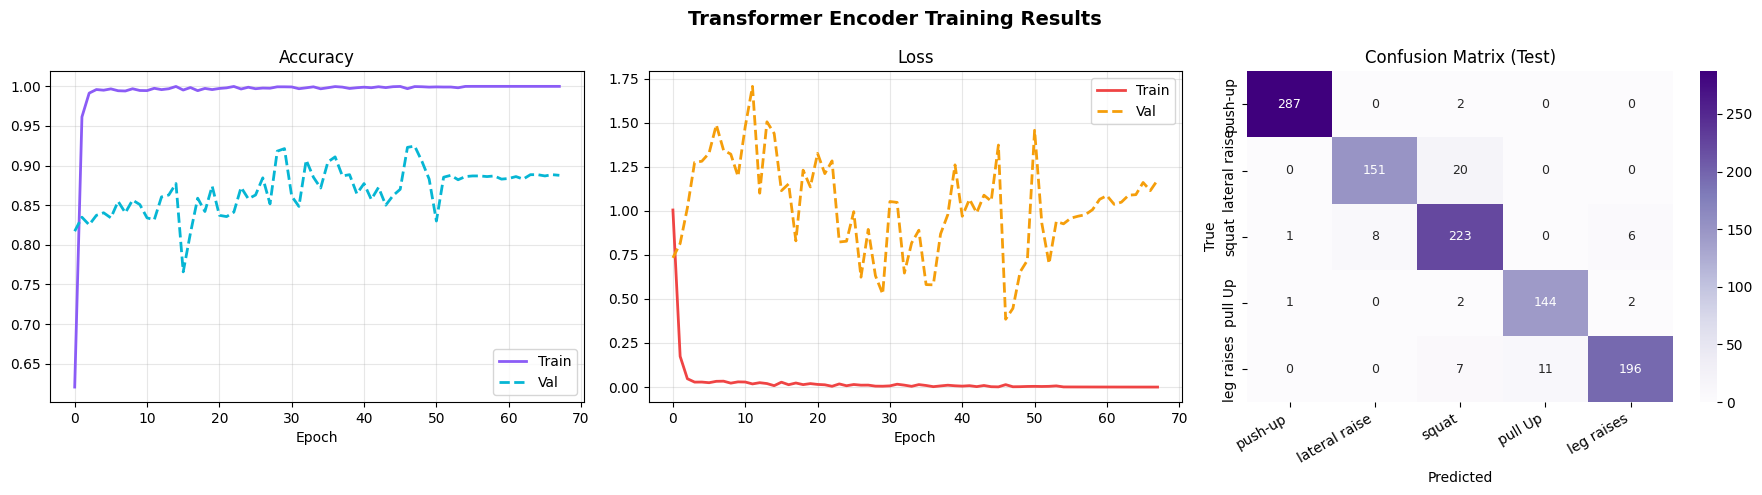

Saved: d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\transformer\training_results.png


In [10]:
# ==== CELL 10: Visualize ====
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Transformer Encoder Training Results', fontsize=14, fontweight='bold')

ax = axes[0]
ax.plot(history.history['accuracy'],     label='Train', color='#8b5cf6', linewidth=2)
ax.plot(history.history['val_accuracy'], label='Val',   color='#06b6d4', linewidth=2, linestyle='--')
ax.set_title('Accuracy'); ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(history.history['loss'],     label='Train', color='#ef4444', linewidth=2)
ax.plot(history.history['val_loss'], label='Val',   color='#f59e0b', linewidth=2, linestyle='--')
ax.set_title('Loss'); ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=0.3)

ax = axes[2]
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=labels, yticklabels=labels, ax=ax,
            annot_kws={'size': 9})
ax.set_title('Confusion Matrix (Test)')
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.xticks(rotation=30, ha='right')

plt.tight_layout()
fig_path = os.path.join(MODEL_DIR, 'training_results.png')
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {fig_path}')

In [11]:
# ==== CELL 11: Lưu summary ====
summary = {
    'model_name'   : 'TransformerEncoder',
    'model_path'   : BEST_MODEL_PATH,
    'best_epoch'   : best_epoch,
    'val_accuracy' : round(best_val_acc, 4),
    'test_accuracy': round(float(test_acc), 4),
    'test_loss'    : round(float(test_loss), 4),
    'total_params' : model.count_params(),
    'hyperparams'  : {
        'embed_dim': EMBED_DIM, 'num_heads': NUM_HEADS,
        'ff_dim': FF_DIM, 'n_blocks': N_BLOCKS, 'dropout': DROPOUT
    },
    'input_shape'  : list(INPUT_SHAPE),
    'n_classes'    : N_CLASSES,
    'label_map'    : LABEL_MAP
}
summary_path = os.path.join(MODEL_DIR, 'model_summary.json')
with open(summary_path, 'w') as f:
    json.dump(summary, f, indent=2)

print('=== TRANSFORMER TRAINING COMPLETE ===')
print(f'Best val accuracy : {best_val_acc*100:.2f}%')
print(f'Test accuracy     : {test_acc*100:.2f}%')
print(f'Model saved       : {BEST_MODEL_PATH}')
print('\n>>> Tiếp theo: chạy 05_comparison.ipynb <<<')

=== TRANSFORMER TRAINING COMPLETE ===
Best val accuracy : 92.46%
Test accuracy     : 94.34%
Model saved       : d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\transformer\best_model.h5

>>> Tiếp theo: chạy 05_comparison.ipynb <<<
